### Question:
# What is the problability of rolling a 1 on a D6?

### My Study
Describe your simulation here:
1. What is the **random process** being simulated?
2. What will one **trial** look like? What are the possible **outcomes** of this trial?
3. What **event** are you interested in? Which outcomes are included in that event?

In [2]:
### My Analysis
# First, write the code you need to simulate rolling your die 1000 times.
# Then, write the code you need to estimate a probability from the simulated data.
# Finally, write the code you need to calculate a theoretical probability.
# Add as many cells as you need for your analysis

In [1]:
import pandas
import numpy
from fractions import Fraction
import matplotlib
import seaborn

from config import DiceConfig

In [2]:
def roll_dice(sides, total):
    # rolls a dice with a specified number of sides for a specified number of times
    rolls = numpy.random.randint(low=1, high=(sides + 1), size=total)
    return pandas.DataFrame(data=rolls, columns=["Roll"])

In [3]:
def dice_sample_space(sides):
    # creates a sample space in a list for a dice with a specified amount of sides
    i = 2
    sample_space = [1]
    while i <= sides:
        sample_space.append(i)
        i+=1
    return sample_space

In [4]:
def relative_frequency(roll, sample_size, sample):
    # calculates the relative frequency of a specified roll
    num_count = (sample["Roll"] == roll).sum()
    val = num_count/sample_size
    return val

In [5]:
def cum_sum_relative_frequency(roll_sum, rows_so_far):
    val = roll_sum / rows_so_far
    return val

In [6]:
def relative_frequency_so_far(roll, data):
    new_data = data.copy()
    is_one = new_data["Roll"] == roll
    cum_sum_of_roll = is_one.cumsum()
    total_rows_so_far = numpy.arange(1, len(new_data) + 1)
    
    new_data["Relative frequency so far"] = cum_sum_relative_frequency(cum_sum_of_roll, total_rows_so_far)
    return new_data

In [13]:
def graph_creation(graph_type, number_of_trials, variable, data):
    # variable: name of column. ex: "Roll" if you want to make a graph with the rolls
    
    # matplotlib.pyplot.
    # seaborn
    if (graph_type == "LINE"):
        plot = seaborn.lineplot(data=data, x=data.index, y=data[variable])
    elif (graph_type == "DOT"):
        pass
    elif (graph_type == "BAR"):
        plot = seaborn.barplot(data=data, x=data.index, y=data[variable])

    return plot

In [7]:
die = DiceConfig.die_number
rolls = DiceConfig.times_rolled
checked_number = DiceConfig.checked_number
graph_types = ("LINE", "DOT", "BAR")
current_roll = roll_dice(die, rolls)
current_roll_size = current_roll.index.size
# current_roll.head()

In [8]:
current_sample_space = dice_sample_space(die)
current_sample_space_size = len(current_sample_space)

In [9]:
ideal_probability = Fraction(1/len(current_sample_space)).limit_denominator()

In [10]:
current_relative_frequency = relative_frequency(checked_number, current_roll_size, current_roll)

In [17]:
current_roll = relative_frequency_so_far(checked_number, current_roll)
# current_roll_with_relative_frequency.head()

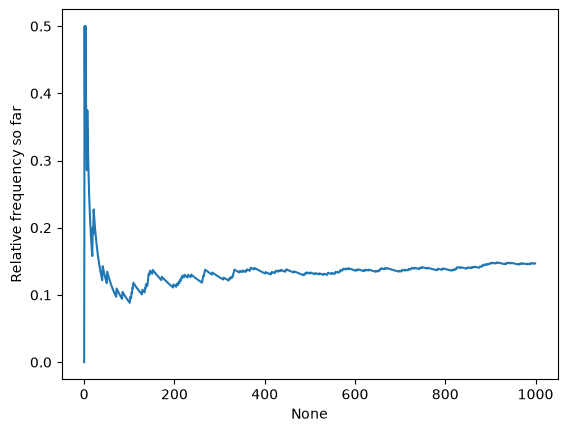

In [18]:
graph = graph_creation(graph_types[0], 1, current_roll.columns[1], current_roll)
matplotlib.pyplot.axhline()

In [12]:
print(f"Number of possible outcomes: {len(current_sample_space)}")
print()
print(f"Ideal probability: {ideal_probability}")
print()
print(f"Relative frequency of {checked_number}: {Fraction(current_relative_frequency).limit_denominator()} (or {round(current_relative_frequency, 3)})")

Number of possible outcomes: 6

Ideal probability: 1/6

Relative frequency of 1: 147/1000 (or 0.147)


### My Conclusion
1. Write your answer here. Your answer should reference at least one empirical probability and one theoretical probability.
2. Include a graph from your analysis here.
3. Interpret the graph above. How does this graph support the answer that you described?